In [22]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator
from qiskit.primitives import StatevectorSampler

In [16]:
solution = "101" # I will have 8 elements with "101" as solution

In [17]:
def oracle(target: str) -> QuantumCircuit:
    if not target or any(bit not in "01" for bit in target):
        raise ValueError("Target must by a nonempty binary string.")

    n = len(target)
    oracle = QuantumCircuit(n, name=f"Oracle({target})")

    zero_qubits = [
        i for i, bit in enumerate(reversed(target)) if bit == "0"
    ] # used reversed because qiskit places qubit 0 on the right

    # Flip the phase of the all-ones state
    for i in zero_qubits:
        oracle.x(i)

    if n == 1:
        oracle.z(0)
    else: # here you use HXH = Z and thus prepare CZ, because you don't have multi-controlled Z gate in Qiskit
        oracle.h(n - 1)
        oracle.mcx(list(range(n - 1)), n - 1)
        oracle.h(n - 1)

    # Undo the mapping
    for i in zero_qubits:
        oracle.x(i)

    return oracle


In [18]:
oracle = oracle(solution)
iteration = grover_operator(oracle)

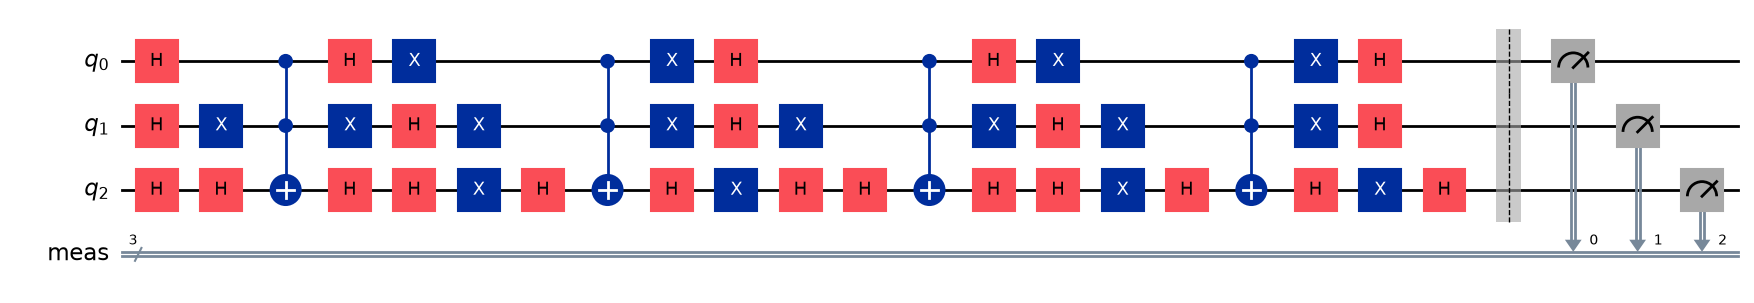

In [21]:
grover = QuantumCircuit(3)

grover.h(range(grover.num_qubits))

for _ in range(2):
    grover.compose(iteration, inplace=True)

grover.measure_all()

grover.draw("mpl")


In [24]:
sampler = StatevectorSampler()
result = sampler.run([grover], shots=1).result()

counts = result[0].data.meas.get_counts()
print(counts)

{'101': 1}
